In [1]:
print("AI Equalizer Benchmark")
print("Phase 1: PAM4 Communication Simulator")

AI Equalizer Benchmark
Phase 1: PAM4 Communication Simulator


In [2]:
import sys
print(sys.version)

3.11.13 (main, Jun  3 2025, 18:38:25) [Clang 17.0.0 (clang-1700.0.13.3)]


In [3]:
import numpy
import scipy
import matplotlib
import pandas
import torch

print("Environment works!")

Environment works!


In [4]:
import numpy as np

# Reproducibility
np.random.seed(42)

# Generate 20 random bits
bits = np.random.randint(0, 2, 20)

print("Random bits:")
print(bits)

Random bits:
[0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1 1 1 0]


In [5]:
# Group bits into pairs
bit_pairs = bits.reshape(-1, 2)

print("Bit pairs:")
print(bit_pairs)

Bit pairs:
[[0 1]
 [0 0]
 [0 1]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 0]
 [1 1]
 [1 0]]


In [6]:
# Gray-coded PAM4 mapping
pam4_mapping = {
    (0, 0): -3,
    (0, 1): -1,
    (1, 1):  1,
    (1, 0):  3
}

symbols = np.array([
    pam4_mapping[tuple(pair)]
    for pair in bit_pairs
])

print("PAM4 symbols:")
print(symbols)

PAM4 symbols:
[-1 -3 -1 -3 -1 -3 -3  3  1  3]


Matplotlib is building the font cache; this may take a moment.


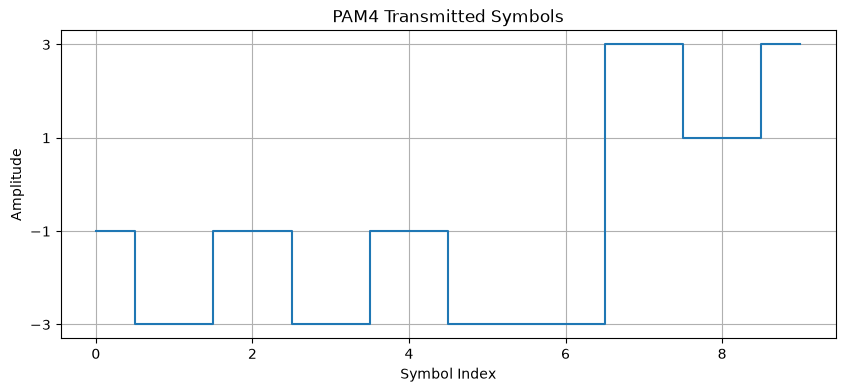

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.step(range(len(symbols)), symbols, where="mid")

plt.xlabel("Symbol Index")
plt.ylabel("Amplitude")
plt.title("PAM4 Transmitted Symbols")
plt.yticks([-3, -1, 1, 3])
plt.grid(True)

plt.show()

In [8]:
# Number of samples used to represent each symbol
samples_per_symbol = 10

# Repeat each PAM4 symbol
tx_waveform = np.repeat(symbols, samples_per_symbol)

print("Number of PAM4 symbols:", len(symbols))
print("Samples per symbol:", samples_per_symbol)
print("Total waveform samples:", len(tx_waveform))

Number of PAM4 symbols: 10
Samples per symbol: 10
Total waveform samples: 100


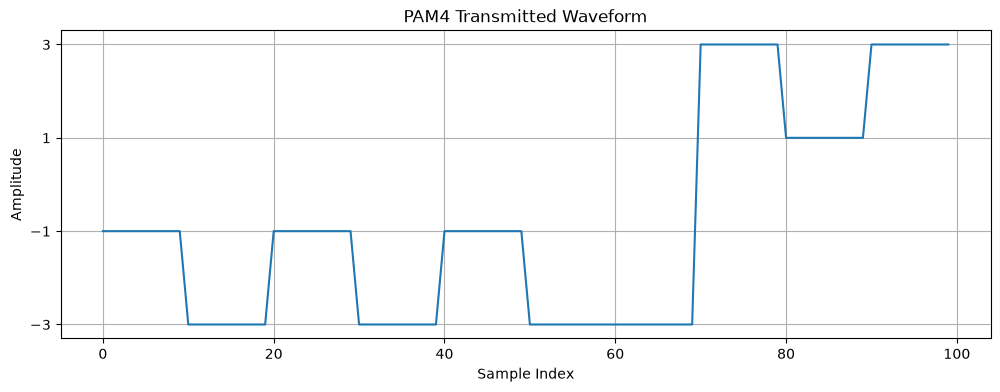

In [9]:
plt.figure(figsize=(12, 4))

plt.plot(tx_waveform)

plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.title("PAM4 Transmitted Waveform")
plt.yticks([-3, -1, 1, 3])
plt.grid(True)

plt.show()

In [11]:
# Simple channel impulse response
channel = np.array([0.1, 0.2, 0.5, 0.2, 0.1])

print("Channel impulse response:")
print(channel)

print("Channel energy:", np.sum(channel**2))

Channel impulse response:
[0.1 0.2 0.5 0.2 0.1]
Channel energy: 0.35


In [12]:
from scipy.signal import convolve

# Pass the transmitted waveform through the channel
rx_noiseless = convolve(tx_waveform, channel, mode="same")

print("Transmitted samples:", len(tx_waveform))
print("Received samples:", len(rx_noiseless))

Transmitted samples: 100
Received samples: 100


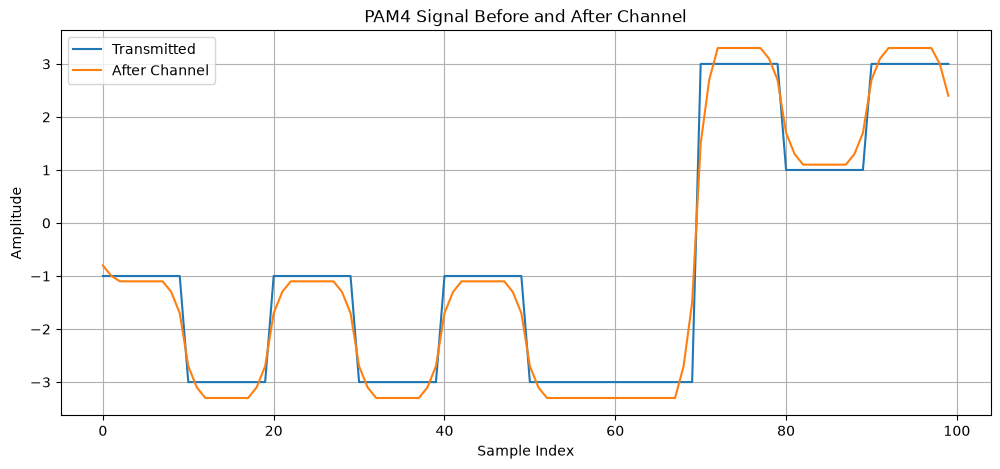

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(tx_waveform, label="Transmitted")
plt.plot(rx_noiseless, label="After Channel")

plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.title("PAM4 Signal Before and After Channel")
plt.legend()
plt.grid(True)

plt.show()

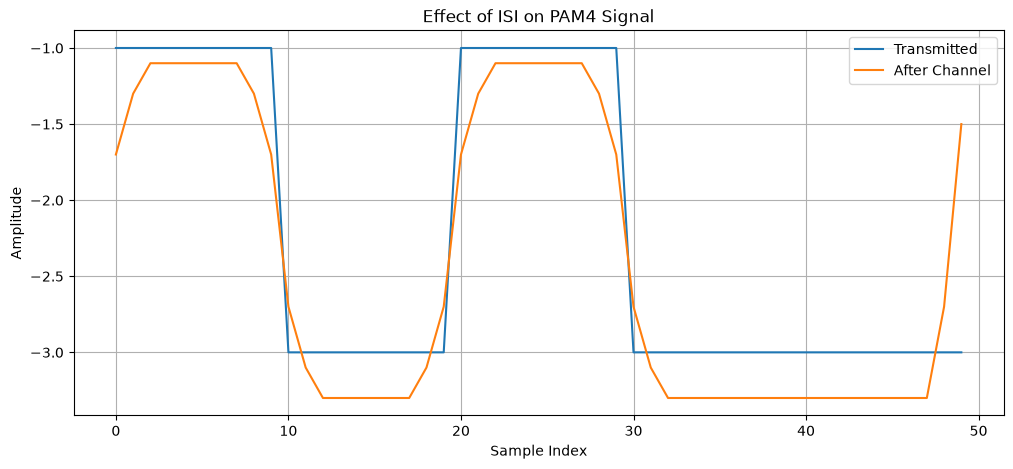

In [14]:
plt.figure(figsize=(12, 5))

start = 20
end = 70

plt.plot(tx_waveform[start:end], label="Transmitted")
plt.plot(rx_noiseless[start:end], label="After Channel")

plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.title("Effect of ISI on PAM4 Signal")
plt.legend()
plt.grid(True)

plt.show()

In [40]:
snr_db = 5

print("SNR:", snr_db, "dB")

SNR: 5 dB


In [72]:
signal_power = np.mean(rx_noiseless**2)

print("Signal power:", signal_power)

Signal power: 6.5048


In [73]:
snr_linear = 10 ** (snr_db / 10)

noise_power = signal_power / snr_linear

print("Noise power:", noise_power)

Noise power: 2.056998372386327


In [81]:
noise = np.random.normal(
    loc=0,
    scale=np.sqrt(noise_power),
    size=len(rx_noiseless)
)

print("Noise mean:", np.mean(noise))
print("Noise standard deviation:", np.std(noise))

Noise mean: 0.007207224799268199
Noise standard deviation: 1.3194436133729506


In [82]:
rx_signal = rx_noiseless + noise
print(rx_signal)

[-3.78595304  1.43309837 -0.79735369 -1.23870826 -1.88153601 -0.52754942
 -1.15397659  0.482382   -1.13617197 -1.48443361 -3.22150135 -3.18167278
 -2.85854333 -5.75276449 -5.23359984 -2.23399283 -3.05494069 -3.56387331
 -3.07356161 -2.20148999 -2.47413627 -2.41626329 -0.81911404 -2.50320568
 -0.51447412 -3.5418862   0.37603968 -0.42218937 -0.93279602 -0.29060104
 -0.31133664 -1.64516615 -5.94022593 -5.13519995 -4.19612978 -3.26257959
 -2.55756103 -4.34087917 -2.83213463 -3.7833883  -2.57705349 -3.31746705
 -2.42412324 -3.03861845 -2.4996208   0.41115831 -2.46165064  2.67542543
 -0.59247165 -1.4349036  -3.9310773  -2.09559879 -4.12559356 -3.1250106
  0.37173459 -3.43777141 -1.65168466 -4.30851248 -3.35018133 -0.7602753
 -4.19921118 -0.70054285 -2.28492522 -4.10670333 -2.39298567 -1.9051391
 -2.40818525 -5.55205392 -3.74287756 -1.85499716  1.39324579  3.59018279
  3.55486303  1.38481712  3.84528887  4.17571671  4.10286487  4.85008161
  4.29603114  3.35856707  1.59936666 -1.08218997  1.71

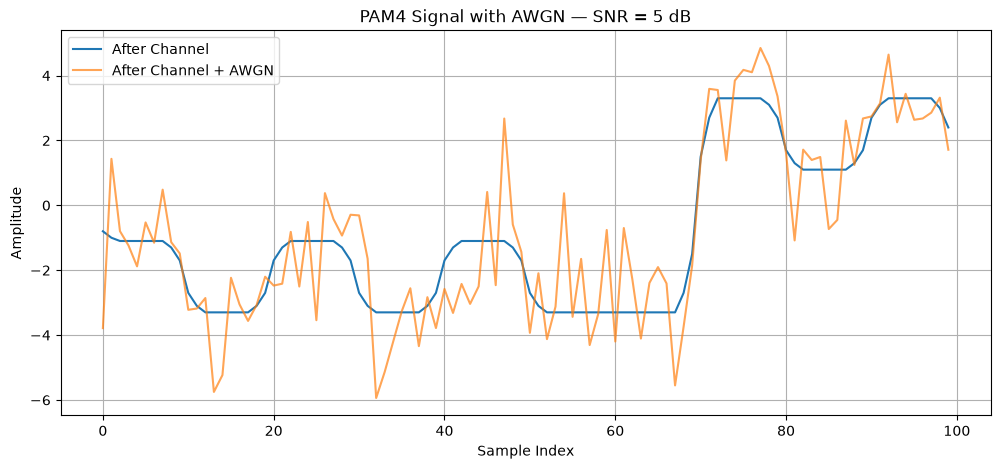

In [83]:
plt.figure(figsize=(12, 5))

plt.plot(rx_noiseless, label="After Channel")
plt.plot(rx_signal, label="After Channel + AWGN", alpha=0.7)

plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.title(f"PAM4 Signal with AWGN — SNR = {snr_db} dB")
plt.legend()
plt.grid(True)

plt.show()

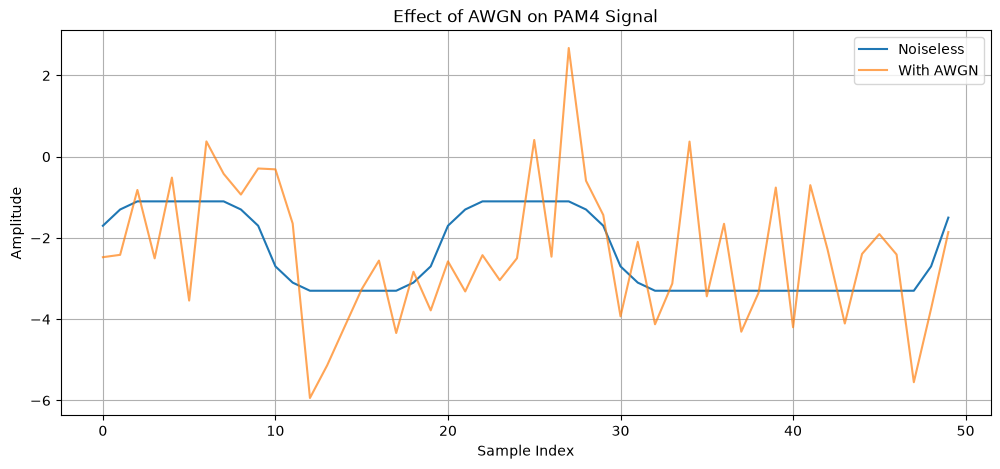

In [84]:
plt.figure(figsize=(12, 5))

start = 20
end = 70

plt.plot(rx_noiseless[start:end], label="Noiseless")
plt.plot(rx_signal[start:end], label="With AWGN", alpha=0.7)

plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.title("Effect of AWGN on PAM4 Signal")
plt.legend()
plt.grid(True)

plt.show()

In [85]:
# Sample at the center of each symbol period
sample_indices = np.arange(samples_per_symbol // 2, len(rx_signal), samples_per_symbol)

rx_samples = rx_signal[sample_indices]

print("Number of received symbols:", len(rx_samples))
print("Received samples:")
print(rx_samples)

Number of received symbols: 10
Received samples:
[-0.52754942 -2.23399283 -3.5418862  -3.26257959  0.41115831 -3.43777141
 -1.9051391   4.17571671 -0.7311434   2.6369937 ]


In [86]:
def pam4_detect(samples):
    detected = np.zeros(len(samples), dtype=int)

    detected[samples < -2] = -3
    detected[(samples >= -2) & (samples < 0)] = -1
    detected[(samples >= 0) & (samples < 2)] = 1
    detected[samples >= 2] = 3

    return detected


detected_symbols = pam4_detect(rx_samples)

print("Detected PAM4 symbols:")
print(detected_symbols)

Detected PAM4 symbols:
[-1 -3 -3 -3  1 -3 -1  3 -1  3]


In [87]:
print("Transmitted symbols:")
print(symbols)

print("\nDetected symbols:")
print(detected_symbols)

Transmitted symbols:
[-1 -3 -1 -3 -1 -3 -3  3  1  3]

Detected symbols:
[-1 -3 -3 -3  1 -3 -1  3 -1  3]


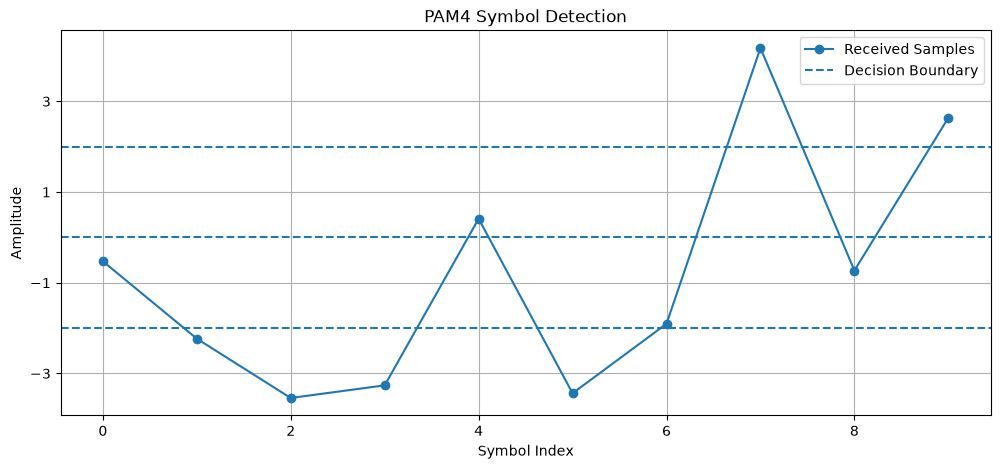

In [88]:
plt.figure(figsize=(12, 5))

plt.plot(rx_samples, "o-", label="Received Samples")
plt.axhline(-2, linestyle="--", label="Decision Boundary")
plt.axhline(0, linestyle="--")
plt.axhline(2, linestyle="--")

plt.yticks([-3, -1, 1, 3])
plt.xlabel("Symbol Index")
plt.ylabel("Amplitude")
plt.title("PAM4 Symbol Detection")
plt.legend()
plt.grid(True)

plt.show()

In [89]:
pam4_to_bits = {
    -3: (0, 0),
    -1: (0, 1),
     1: (1, 1),
     3: (1, 0)
}

detected_bits = np.array([
    bit
    for symbol in detected_symbols
    for bit in pam4_to_bits[symbol]
])

print("Original bits:")
print(bits)

print("\nDetected bits:")
print(detected_bits)

Original bits:
[0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1 1 1 0]

Detected bits:
[0 1 0 0 0 0 0 0 1 1 0 0 0 1 1 0 0 1 1 0]


In [90]:
bit_errors = bits != detected_bits

print("Bit errors:")
print(bit_errors.astype(int))

print("Number of bit errors:", np.sum(bit_errors))

Bit errors:
[0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 1 0 0 0]
Number of bit errors: 4


In [91]:
ber = np.mean(bit_errors)

print("BER:", ber)

BER: 0.2


In [92]:
print("========== BER RESULTS ==========")
print(f"Total bits: {len(bits)}")
print(f"Bit errors: {np.sum(bit_errors)}")
print(f"BER: {ber:.6f}")

========== BER RESULTS ==========
Total bits: 20
Bit errors: 4
BER: 0.200000


In [93]:
# Number of bits for BER experiments
num_bits = 100_000

# Generate random bits
bits_large = np.random.randint(0, 2, num_bits)

print("Number of bits:", len(bits_large))

Number of bits: 100000


In [94]:
# Group bits into pairs
bit_pairs_large = bits_large.reshape(-1, 2)

# Map bit pairs to PAM4 symbols
symbols_large = np.array([
    pam4_mapping[tuple(pair)]
    for pair in bit_pairs_large
])

print("Number of PAM4 symbols:", len(symbols_large))

Number of PAM4 symbols: 50000


In [95]:
tx_waveform_large = np.repeat(symbols_large, samples_per_symbol)

print("Waveform samples:", len(tx_waveform_large))

Waveform samples: 500000


In [96]:
snr_values = np.arange(0, 21, 2)

print("SNR values:", snr_values)

SNR values: [ 0  2  4  6  8 10 12 14 16 18 20]


In [98]:
def simulate_pam4_ber(bits, snr_db, channel, samples_per_symbol):
    # PAM4 mapping
    bit_pairs = bits.reshape(-1, 2)

    symbols = np.array([
        pam4_mapping[tuple(pair)]
        for pair in bit_pairs
    ])

    # Oversample
    tx_waveform = np.repeat(symbols, samples_per_symbol)

    # Channel
    rx_noiseless = convolve(tx_waveform, channel, mode="same")

    # Calculate signal power
    signal_power = np.mean(rx_noiseless ** 2)

    # Convert SNR from dB to linear
    snr_linear = 10 ** (snr_db / 10)

    # Calculate noise power
    noise_power = signal_power / snr_linear

    # Generate AWGN
    noise = np.random.normal(
        0,
        np.sqrt(noise_power),
        len(rx_noiseless)
    )

    # Received signal
    rx_signal = rx_noiseless + noise

    # Sample at center of each symbol
    sample_indices = np.arange(
        samples_per_symbol // 2,
        len(rx_signal),
        samples_per_symbol
    )

    rx_samples = rx_signal[sample_indices]

    # PAM4 detection
    detected_symbols = pam4_detect(rx_samples)

    # Convert detected symbols back to bits
    detected_bits = np.array([
        bit
        for symbol in detected_symbols
        for bit in pam4_to_bits[symbol]
    ])

    # Make sure lengths match
    detected_bits = detected_bits[:len(bits)]

    # Calculate BER
    bit_errors = np.sum(bits != detected_bits)
    ber = bit_errors / len(bits)

    return ber

In [99]:
ber_results = []

for snr_db in snr_values:
    ber = simulate_pam4_ber(
        bits_large,
        snr_db,
        channel,
        samples_per_symbol
    )

    ber_results.append(ber)

    print(f"SNR = {snr_db:2d} dB | BER = {ber:.6f}")

SNR =  0 dB | BER = 0.279780
SNR =  2 dB | BER = 0.227270
SNR =  4 dB | BER = 0.178830
SNR =  6 dB | BER = 0.133030
SNR =  8 dB | BER = 0.089610
SNR = 10 dB | BER = 0.053170
SNR = 12 dB | BER = 0.026700
SNR = 14 dB | BER = 0.009240
SNR = 16 dB | BER = 0.002270
SNR = 18 dB | BER = 0.000270
SNR = 20 dB | BER = 0.000000


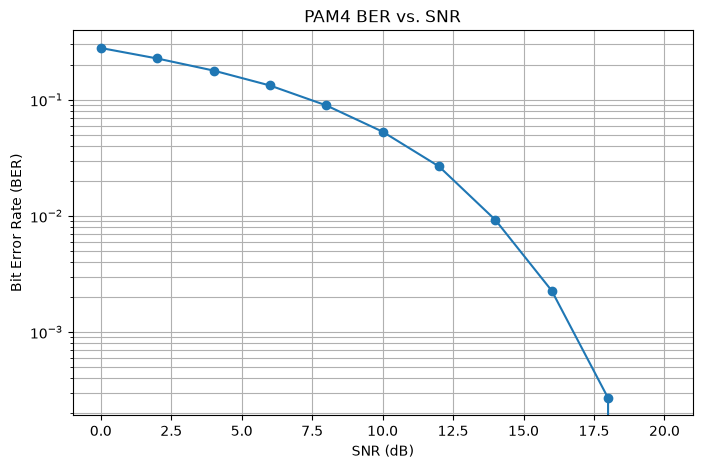

In [100]:
plt.figure(figsize=(8, 5))

plt.semilogy(snr_values, ber_results, "o-")

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("PAM4 BER vs. SNR")
plt.grid(True, which="both")

plt.show()

In [105]:
import pandas as pd
baseline_results = pd.DataFrame({
    "SNR_dB": snr_values,
    "BER": ber_results
})

baseline_results

,SNR_dB,BER
0,0,0.27978
1,2,0.22727
2,4,0.17883
3,6,0.13303
4,8,0.08961
5,10,0.05317
6,12,0.02670
7,14,0.00924
8,16,0.00227
9,18,0.00027


In [106]:
baseline_results.to_csv("../results/baseline_ber.csv", index=False)

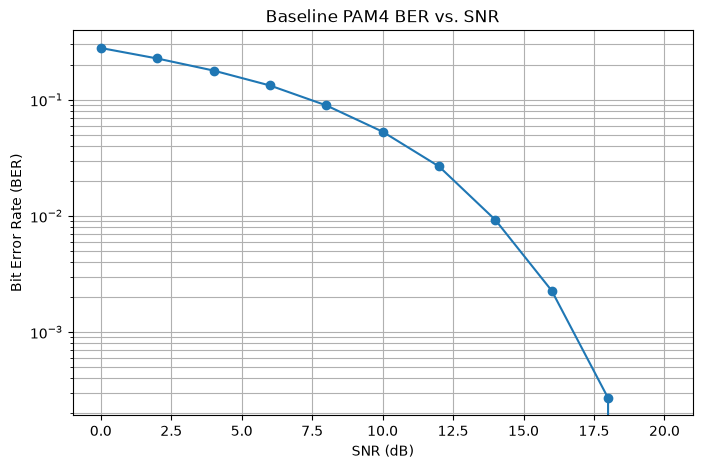

In [107]:
plt.figure(figsize=(8, 5))

plt.semilogy(snr_values, ber_results, "o-")

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("Baseline PAM4 BER vs. SNR")
plt.grid(True, which="both")

plt.savefig("../figures/baseline_ber_vs_snr.png", dpi=300, bbox_inches="tight")
plt.show()